# Global Superstore Data Analysis

## 1. Project Introduction

The Global Superstore dataset contains transactional information covering sales, products, customers, markets, shipping, discounts, and profitability.

This project applies **Python and Pandas** to assess the quality of the dataset, prepare the data for analysis, explore important patterns, and generate business-oriented insights.

The project follows a structured data analysis workflow:

1. Dataset loading and structure assessment
2. Missing value assessment
3. Duplicate assessment
4. Data type assessment
5. Invalid and suspicious value assessment
6. Categorical consistency assessment
7. Numerical data quality assessment
8. Date quality assessment
9. Final data quality assessment
10. Data cleaning and preparation
11. Exploratory Data Analysis (EDA)
12. Focused profitability analysis
13. Data visualization
14. Final quality checks and documentation

### Analytical Focus

The dataset contains many possible analytical dimensions. After conducting the initial exploratory analysis, this project focuses specifically on **profitability and the factors associated with profit**.

The analysis examines profitability across selected business dimensions, including:

- Product Category
- Market
- Discount
- Sales
- Negative-profit transactions

The objective is to identify where profit is generated, where losses are concentrated, and which business factors are associated with changes in profitability.

### Project Objective

The main objective of this analysis is to transform the raw Global Superstore data into reliable, meaningful, and business-relevant insights while demonstrating practical use of Pandas for data assessment, cleaning, exploratory analysis, and visualization.

In [5]:
# importing libraries

import pandas as pd
import numpy as np

## 1. Load and Explore The Data

In [1]:
# load python's operating tools
import os
print(os.getcwd())

c:\Users\admin\OneDrive\Documents\Global_Superstore_Sales_and_Profitabilty_Analysis\notebook


In [3]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [6]:
df = pd.read_excel("../data/Global Superstore Data - Copy.xlsx")

### Finding -Dataset Dimensions Inspection:


In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Product Name,Sub-Category,Category,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,24599,IN-2017-CA120551-42816,2017-03-22,2017-03-29,Standard Class,CA-120551,Cathy Armstrong,Home Office,NaN,Herat,...,FUR-BO-4861,"Ikea Library with Doors, Mobile",Bookcases,Furniture,731.82,2,0.0,102.42,39.66,Medium
1,29465,ID-2015-BD116051-42248,2015-09-01,2015-09-04,Second Class,BD-116051,Brian Dahlen,Consumer,NaN,Herat,...,OFF-SU-2988,"Acme Scissors, Easy Grip",Supplies,Office Supplies,243.54,9,0.0,104.49,18.72,Medium
2,24598,IN-2017-CA120551-42816,2017-03-22,2017-03-29,Standard Class,CA-120551,Cathy Armstrong,Home Office,NaN,Herat,...,TEC-MA-4211,"Epson Receipt Printer, White",Machines,Technology,346.32,3,0.0,13.77,14.10,Medium
3,24597,IN-2017-CA120551-42816,2017-03-22,2017-03-29,Standard Class,CA-120551,Cathy Armstrong,Home Office,NaN,Herat,...,FUR-FU-5726,"Rubbermaid Door Stop, Erganomic",Furnishings,Furniture,169.68,4,0.0,79.68,11.01,Medium
4,29464,ID-2015-BD116051-42248,2015-09-01,2015-09-04,Second Class,BD-116051,Brian Dahlen,Consumer,NaN,Herat,...,OFF-EN-3664,"Cameo Interoffice Envelope, with clear poly wi...",Envelopes,Office Supplies,203.88,4,0.0,24.36,5.72,Medium


In [7]:
df.shape

(51290, 24)

### Results:

- 51290 rows

- 24 columns

### Findings:

The Global Superstore dataset contains 51,290 records and 24 variables.each row represents an individual transaction/record, while the 24 columns contain the associated customer, product, sales, shipping, and other attributes.

### Interpretation:
The datset is sufficiently large for meaningful explanatory and business analysis. The 24 variables provide information about orders, customers, products, locations, sales, profit, shipping, and other transaction characteristics.


In [8]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Postal Code', 'City',
       'State', 'Country', 'Region', 'Market', 'Product ID', 'Product Name',
       'Sub-Category', 'Category', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Shipping Cost', 'Order Priority'],
      dtype='str')

## 2.  Clean and Prepare the Data

In [97]:
df_clean = df.copy()
df_clean.shape

(51290, 24)

In [98]:
df_clean.columns = df_clean.columns.str.strip()

In [99]:
df_clean.columns = df_clean.columns.str.strip()


In [100]:
df_clean.shape

(51290, 24)

### Missing values

In [9]:
df.isnull().sum()

Row ID                0
Order ID              0
Order Date            0
Ship Date             0
Ship Mode             0
Customer ID           0
Customer Name         0
Segment               0
Postal Code       41296
City                  0
State                 0
Country               0
Region                0
Market                0
Product ID            0
Product Name          0
Sub-Category          0
Category              0
Sales                 0
Quantity              0
Discount              0
Profit                0
Shipping Cost         0
Order Priority        0
dtype: int64

In [10]:
df["Postal Code"].isnull().sum()

np.int64(41296)

In [11]:
df["Postal Code"].isnull().mean() * 100

np.float64(80.51472021836615)

In [12]:
df[df["Postal Code"].isnull()]["Country"].unique()
df[df["Postal Code"].notnull()]["Country"].unique()

<StringArray>
['United States']
Length: 1, dtype: str

In [13]:
print(df[df["Postal Code"].isnull()]["Country"].unique())
df[df["Country"] == "United States"]["Postal Code"].isnull().sum()

<StringArray>
[         'Afghanistan',              'Albania',              'Algeria',
               'Angola',            'Argentina',              'Armenia',
            'Australia',              'Austria',           'Azerbaijan',
              'Bahrain',
 ...
 'United Arab Emirates',       'United Kingdom',              'Uruguay',
           'Uzbekistan',            'Venezuela',              'Vietnam',
       'Western Sahara',                'Yemen',               'Zambia',
             'Zimbabwe']
Length: 164, dtype: str


np.int64(0)

### Duplicates

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["Row ID"].duplicated().sum()

np.int64(0)

In [16]:
df.dtypes

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Postal Code              float64
City                         str
State                        str
Country                      str
Region                       str
Market                       str
Product ID                   str
Product Name                 str
Sub-Category                 str
Category                     str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
Shipping Cost            float64
Order Priority               str
dtype: object

In [17]:
df["Postal Code"].dropna().head()

40553    36830.0
40554    36830.0
40555    36830.0
40556    36830.0
40557    36830.0
Name: Postal Code, dtype: float64

In [18]:
(df["Postal Code"].dropna() % 1 != 0).sum()

np.int64(0)

## Data Quality Assessment Finding and Decisions

### 2.1 Postal Code

**Finding:**

The 'Postal Code' column contains **41,296 missing values**, representing approximately **80.5%** of the dataset. All other columns contain **0 missing values**. Further investigation showed that missing postal code values occur a cross**164 countries**, while non missing postal code values are concentrated in the United States.


**Interpretation:**

The missing Postal Code values are systimatic rather than random. The patterns suggests that the postal code information is primarily for United States records and is not consistently provided for international records.

**Data Quality Decisions:**

The missing Postal Code values will be retained as missing values rather than being arbitrarily imputed. The dataset does not provide sufficient information to determine the actual missing postal codes. Therefore, no values will be invented or assigned to the missing records.

## 2.2 Duplicate Records Assessment

### Exact Duplicate Records

**Findings:**

The check for completely duplicated rows returned **0 duplicates results**.

**interpretation:**

No records in the dataset are exact copies of another complete record. Therefore there is no evidence of accidental duplication at the full-row level.

### Row ID Uniqueness

**Finding:**

The `Row ID` contains **0 duplicates values**.

**Interpretation:**

Each record has a unique `Row ID`, providing additional evidance that the dataset does not contain duplicate records based on its primary row identifier.

**Data Quality Decision:**

No duplicate records require removal at this stage.

## 2.3. Data Type Assessment

**Finding:**

The majority of columns have appropriate data types for analysis.

The main data issue identified is the `postal Code` column, which is stored as `float64`. Further investigation showed that the non missing `postal code` values are whole numbers, with **no values containing fractional component**. 

**Interpretation:**

The `float64` representation of Postal Code is primarily a consequence of the column containing missing values. Value such as `36830.0` represented the whole number postal code rather than meaningful decimal measurement.
Postal Code is also an identify rather a numerical measure, meaning mathematical operations on it would not have analytical meaning.

**Data Quality Decision**

The postal code should ultimately be treated as an identifier rather than continuous numerical variables. However,the actual conversion will be performed during the dedicated data cleaning stage rather than during the assessment stage.

## 3 . Perfom Operations on the Data

### 3.1 Sales

In [19]:

df["Sales"].describe()

count    51290.000000
mean       246.490581
std        487.565361
min          0.444000
25%         30.758625
50%         85.053000
75%        251.053200
max      22638.480000
Name: Sales, dtype: float64

In [20]:
print("Negative Sales:",(df["Sales"] < 0).sum())
print("Zero Sales:",(df["Sales"] == 0).sum())
print("Missing Sales:",(df["Sales"].isna().sum()))

Negative Sales: 0
Zero Sales: 0
Missing Sales: 0


**Finding:**

The `Sales` column contains no ngative values, zero values, or missing values. T.he minimum recorded sales value is 0.44 while the maximum is 22,638.48.

**Interpretation:**

All recorded transactions have positive sales values, and the column is complete. Athough the maximum values has substantially higher than the median, a large value is not necessarily invalid and may represent  alegitimate high-value transaction.

**Data Quality Decision** 

No invalid Sales were identified at this stage. The Sales column will be retained without modification during data cleaning

### 3.2  Profit

In [21]:
df["Profit"].describe()

count    51290.000000
mean        28.610982
std        174.340972
min      -6599.978000
25%          0.000000
50%          9.240000
75%         36.810000
max       8399.976000
Name: Profit, dtype: float64

In [22]:
print("Negative Profit:",(df["Profit"] < 0).sum())
print("Zero Profit:",(df["Profit"] == 0).sum())
print("Missing Profit:",(df["Profit"].isna().sum()))

Negative Profit: 12544
Zero Profit: 668
Missing Profit: 0


In [23]:
# relationship between sales and profit
df.loc[df["Profit"] < 0,["Sales", "Profit"]].describe()

,Sales,Profit
count,12544.000000,12544.000000
mean,198.502681,-73.393348
std,423.779161,186.222175
min,0.444000,-6599.978000
25%,21.420000,-65.340000
50%,64.543500,-21.206250
75%,206.685000,-6.899200
max,22638.480000,-0.000900


In [24]:
df.loc[df["Profit"] == df["Profit"].min(),["Sales", "Profit"]]

,Sales,Profit
47386,4499.985,-6599.978


In [25]:
df.loc[47386]

Row ID                                                39069
Order ID                           CA-2016-CS12505140-42700
Order Date                              2016-11-26 00:00:00
Ship Date                               2016-12-03 00:00:00
Ship Mode                                    Standard Class
Customer ID                                    CS-125051406
Customer Name                                 Cindy Stewart
Segment                                            Consumer
Postal Code                                         43130.0
City                                              Lancaster
State                                                  Ohio
Country                                       United States
Region                                           Eastern US
Market                                                 USCA
Product ID                                      TEC-MA-3854
Product Name      Cubify CubeX 3D Printer Double Head Print
Sub-Category                            

In [26]:
df[["Discount","Profit"]].corr()

,Discount,Profit
Discount,1.00000,-0.31649
Profit,-0.31649,1.00000


In [27]:
df.groupby("Discount")["Profit"].mean()

Discount
0.000      61.039514
0.002     125.762649
0.070     140.990022
0.100      63.683426
0.150      50.602409
0.170      38.317107
0.200      23.552594
0.202     -14.518847
0.250       4.043371
0.270      -4.317213
0.300     -57.899557
0.320     -88.560656
0.350    -116.144693
0.370     -78.462191
0.400     -45.246603
0.402    -109.908138
0.450     -41.610973
0.470     -42.982420
0.500     -97.140158
0.550    -315.067200
0.570    -526.129000
0.600     -81.732147
0.602    -213.279085
0.650    -365.997971
0.700    -104.339576
0.800    -122.203244
0.850   -1534.329000
Name: Profit, dtype: float64

In [28]:
df.groupby("Discount")["Profit"].agg(["mean", "count"])

,mean,count
Discount,,
0.000,61.039514,29009
0.002,125.762649,461
0.070,140.990022,150
0.100,63.683426,4068
0.150,50.602409,541
0.170,38.317107,735
0.200,23.552594,4998
0.202,-14.518847,41
0.250,4.043371,198


**Finding** 

The analysis indicates that increasing discount levels are generally associated with declining profitability.While some lower discount level remain profitable, average profit becomes negative at several higher discount levels, including 27%, 30%, 35%, 40%, and 47%. The 40% discount level is particularly significant becouse it combines  negative average profit(-45.25) with relatively large transaction volume(3,177) 

**Interpretation**

The evidence suggests that the aggressive discounts may be eroding profit margins. Discounts should therefore  be reviewed carefully, particularly at higher levels,to determine whether the additional sales generated by these discounts compensate for the reduction in profit per transaction.

## 4. Combine the Dataset

In [94]:
file_path = r"C:\Users\admin\OneDrive\Desktop\python-class\data\Global Superstore Data - Copy.xlsx"

excel_file = pd.ExcelFile(file_path)

excel_file.sheet_names

['Orders', 'Returns', 'People']

In [93]:
returns = pd.read_excel(file_path, sheet_name="Returns")

In [92]:
df_returns = df.merge(
    returns[['Order ID', 'Returned']],
    on='Order ID',
    how='left'
)

### Section 4: Combining Datasets

The Orders and Returns datasets were combined using the `merge()` function.

The datasets were joined using `Order ID`, which is the common identifier in both datasets. A left merge was used so that all records from the Orders dataset were retained while return information was added where a matching Order ID existed.

The merged dataset included the `Returned` field from the Returns dataset.

## 5. Group and Aggregate the data

In [95]:
categorical_cols = df.select_dtypes(include="object").columns
categorical_cols

C:\Users\admin\AppData\Local\Temp\ipykernel_6724\3430876840.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


Index(['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment',
       'City', 'State', 'Country', 'Region', 'Market', 'Product ID',
       'Product Name', 'Sub-Category', 'Category', 'Order Priority'],
      dtype='str')

In [30]:
df[categorical_cols].nunique().sort_values()

Segment               3
Category              3
Ship Mode             4
Order Priority        4
Market                5
Sub-Category         17
Region               23
Country             165
Customer Name       796
State              1106
City               3650
Product ID         3788
Product Name       3788
Customer ID       17415
Order ID          25728
dtype: int64

In [31]:
for col in ["Segment", "Category", "Ship Mode",  "Order Priority", "Market"]:
    print(f"\n{col}:")
    print(df[col].unique())


Segment:
<StringArray>
['Home Office', 'Consumer', 'Corporate']
Length: 3, dtype: str

Category:
<StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str

Ship Mode:
<StringArray>
['Standard Class', 'Second Class', 'First Class', 'Same Day']
Length: 4, dtype: str

Order Priority:
<StringArray>
['Medium', 'High', 'Low', 'Critical']
Length: 4, dtype: str

Market:
<StringArray>
['Asia Pacific', 'Europe', 'Africa', 'LATAM', 'USCA']
Length: 5, dtype: str


In [32]:
for col in categorical_cols:
    print(f"{col}:{df[col].str.strip().ne(df[col]).sum()} values with leading/ trailing spaces")

Order ID:0 values with leading/ trailing spaces
Ship Mode:0 values with leading/ trailing spaces
Customer ID:0 values with leading/ trailing spaces
Customer Name:0 values with leading/ trailing spaces
Segment:0 values with leading/ trailing spaces
City:0 values with leading/ trailing spaces
State:0 values with leading/ trailing spaces
Country:0 values with leading/ trailing spaces
Region:0 values with leading/ trailing spaces
Market:0 values with leading/ trailing spaces
Product ID:0 values with leading/ trailing spaces
Product Name:0 values with leading/ trailing spaces
Sub-Category:0 values with leading/ trailing spaces
Category:0 values with leading/ trailing spaces
Order Priority:0 values with leading/ trailing spaces


**Finding:**
 No case, capitalization, or leading/trailing whitespace inconsistencies were detected across the categotrical columns.

 **Interpretation**

 The categorical values are consistently formatted with respect to leading and trailling spaces.No trimming or whitespace correction is required

In [33]:
for col in categorical_cols: normalized = df[col].str.lower().str.strip()
duplicates = normalized.nunique() > df[col].nunique()
print(f"{col}: case/space inconsistencies detected = {duplicates}")

Order Priority: case/space inconsistencies detected = False


In [34]:
case_space_issues = {}
for column in categorical_cols: normalized = df[col].str.strip()
case_space_issues[col] = normalized.nunique() < df[col].nunique()
case_space_issues

{'Order Priority': False}

In [35]:
categorical_cols = df.select_dtypes(include="object").columns
categorical_cols

C:\Users\admin\AppData\Local\Temp\ipykernel_6724\3430876840.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


Index(['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment',
       'City', 'State', 'Country', 'Region', 'Market', 'Product ID',
       'Product Name', 'Sub-Category', 'Category', 'Order Priority'],
      dtype='str')

In [36]:
categorical_cols = df.select_dtypes(include=["object", "str"]).columns
case_space_issues = {}
for col in categorical_cols: 
    normalized = df[col].str.strip().str.lower()
    case_space_issues[col] = normalized.nunique() < df[col].nunique()
case_space_issues

{'Order ID': False,
 'Ship Mode': False,
 'Customer ID': False,
 'Customer Name': False,
 'Segment': False,
 'City': False,
 'State': False,
 'Country': False,
 'Region': False,
 'Market': False,
 'Product ID': False,
 'Product Name': False,
 'Sub-Category': False,
 'Category': False,
 'Order Priority': False}

## 6. Numerical Data Quality Assesssment.

In [37]:
numeric_cols = df.select_dtypes(include="number").columns
numeric_cols

Index(['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Shipping Cost'],
      dtype='str')

In [38]:
df[numeric_cols].agg(["min","max"])

,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
min,1,1040.0,0.444,1,0.00,-6599.978,1.002
max,51290,99301.0,22638.480,14,0.85,8399.976,933.570


**Finding:**

Numerical variables show generally  plausible ranges. Quantity, Sales, and Shipping cost contain positive values, while profit includes both positive and negative values.The negative value has already been investicated and represent legitimate business losses rather than obvious data entry errors. Discount range from 0% to 85% with the upper range warranting attention but not automatic correction.


**Interprtation**

The numerical fields appear broadly suitabl for analysis based on their observed minimum and maximum values. No numerical values should be removed solely  beecause they are unusually high or negative; futher assessment should be based on the meaning of each variable.

## 6. Data Quality assessment

In [39]:
Date_cols = df.select_dtypes(include="datetime").columns
Date_cols

Index(['Order Date', 'Ship Date'], dtype='str')

In [40]:
df[Date_cols].agg(["min", "max"])

,Order Date,Ship Date
min,2014-01-01,2014-01-03
max,2017-12-31,2018-01-07


In [41]:
df["Order Date"].sort_values().diff().value_counts().head(10)

Order Date
0 days    49861
1 days     1396
2 days       32
Name: count, dtype: int64

In [42]:
df["Ship Date"].sort_values().diff().value_counts().head()

Ship Date
0 days    49827
1 days     1459
2 days        3
Name: count, dtype: int64

In [43]:
(df["Ship Date"] < df["Order Date"]).sum()

np.int64(0)

## 7. Final Data Quality Assessment

### Finding

The Global Superstore dataset was assessed across structure, missing values, duplicates, datatypes,invalid/suspecious values, categorical consistency, numerical ranges, and data quality.

The assessment identified 41,296 missing Postal Code values (approximately 80.51%), while other columns had no missing values. The missing Postal Codes are systematic and concentrated outside the United States; therefore, they should be preserved as missing rather than imputed.

No exact duplicate row were identified, and there were no duplicates Row IDs.

The categorical assessment found no obvious spelling, capitalization, leading/trailing whitespace, or case-based  inconsistencies.

Numerical variables showed generally plausible ranges. Negative profit values were investigated and were found to represent legitimate businness loses rather than data-entry errors.

The date assessment showed logically consistent Order Date and Ship Date ranges. No Ship Date occured before its corresponding Order Date

### Interpretation

Overally, the dataset is structurally suitable for further analysis. The main data quality issue requiring attention is the substantial missingness in Postal Code. Because this missingness is systimatic rather than established error, the values should remain missing during the assessment and cleanig stage.

The remaining assesed  fields showed no major structural or consistency issue that woul prevent further analysis.

### Data Quality Conclusion

The dataset is suitable to proceed to the next stage, with the misssing Postal Code values documented and preserved appropriately. Any cleaning performed should be based on the findings established during this assessment rather than arbitrarily replacement of valid or meaningful values.



##  8. Exploratary Data Analysis

In [49]:
df_clean.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00000,51290,51290,9994.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,2016-05-11 11:52:18.436342,2016-05-15 11:09:41.306297,55190.379428,246.490581,3.476545,0.142908,28.610982,26.478567
min,1.00000,2014-01-01 00:00:00,2014-01-03 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,1.002000
25%,12823.25000,2015-06-19 00:00:00,2015-06-23 00:00:00,23223.000000,30.758625,2.000000,0.000000,0.000000,2.610000
50%,25645.50000,2016-07-08 00:00:00,2016-07-12 00:00:00,56430.500000,85.053000,3.000000,0.000000,9.240000,7.790000
75%,38467.75000,2017-05-22 00:00:00,2017-05-26 00:00:00,90008.000000,251.053200,5.000000,0.200000,36.810000,24.450000
max,51290.00000,2017-12-31 00:00:00,2018-01-07 00:00:00,99301.000000,22638.480000,14.000000,0.850000,8399.976000,933.570000
std,14806.29199,NaN,NaN,32063.693350,487.565361,2.278766,0.212280,174.340972,57.251373


### EDA 1 - Numerical Summary

The numerical summary shows that thee dataset contains 51,290 records.Sales are right-skewed, with the mean (246.49) substantially higher than the median (85.05), indicating the presence of relatively high-value transactions.

Quantity has a mean of approximately 3.48 units and a median of 3 units, suggesting that more transaction involve relatively small quantities.

Disounts has a median of 0, indicating that atleast half of the transactions received no discount.

Profit range from approximately -6,599.98 to 8,399.98, cornifirming presence of both profitable and loss-making transctions.

The Postal Code field has substantial, missingness which was already identified during the data assessment and is therefore retained rather than arbitrarily imputed

The date filds cover the period from 2014 to 2017 for orders, with shipping date extending into january 2018.

### EDA 2 - Categorical Distribution


In [50]:
categorical_cols = df_clean.select_dtypes(include=["object", "str"]).columns
df_clean[categorical_cols].nunique().sort_values()

Segment               3
Category              3
Ship Mode             4
Order Priority        4
Market                5
Sub-Category         17
Region               23
Country             165
Customer Name       796
State              1106
City               3650
Product ID         3788
Product Name       3788
Customer ID       17415
Order ID          25728
dtype: int64

### Finding

The dataset contains a small number of high-level business categories , such as 3 segments, 3 product categories, 4 shipping modes and 5 markets.At the same time, it contains much greater variety at the geographic, customer, product , and order levels

### Interpretation

This indicate that the dataset supports analysis at multiple levels:
- **Business level:** Segment, Category, Market.

- **Operational Level:** Ship Mode, Order,Priority

- **Product Level:** Sub Category, Product Name

- **Geographic Level:** Region, County, State, City

- **Customer Level:** Customer ID and Customer Name

- **Transaction Level:** Order ID

To examine how records are distributed among categorical variables.

In [51]:
for col in ["Segment", "Category", "Ship Mode",  "Order Priority", "Market"]:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())


Segment:
Segment
Consumer       26518
Corporate      15429
Home Office     9343
Name: count, dtype: int64

Category:
Category
Office Supplies    31289
Technology         10141
Furniture           9860
Name: count, dtype: int64

Ship Mode:
Ship Mode
Standard Class    30775
Second Class      10309
First Class        7505
Same Day           2701
Name: count, dtype: int64

Order Priority:
Order Priority
Medium      29433
High        15501
Critical     3932
Low          2424
Name: count, dtype: int64

Market:
Market
Asia Pacific    14302
Europe          11729
USCA            10378
LATAM           10294
Africa           4587
Name: count, dtype: int64


**Finding:**

 Consumer is the largest customer segment accoynting for about half of the record,while Home Office is the smallest.

 *Finding:**

 Office supplies dominates the dataset, representing substancially more records than either Technology or furniture.
 

### EDA 3 - Relationships Among Numerical Variabbles

In [52]:
numeric_analysis_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]
df_clean[numeric_analysis_cols].corr()

,Sales,Quantity,Discount,Profit,Shipping Cost
Sales,1.000000,0.313577,-0.086722,0.484918,0.767835
Quantity,0.313577,1.000000,-0.019875,0.104365,0.271804
Discount,-0.086722,-0.019875,1.000000,-0.316490,-0.078153
Profit,0.484918,0.104365,-0.316490,1.000000,0.354423
Shipping Cost,0.767835,0.271804,-0.078153,0.354423,1.000000


**Finding 1:**

Sales and Profit have a moderate positive relationship(r= 0.485),suggesting that higher sales generally correspond to higher profit,although sales alone do not fully explain profitability.

**Finding 2:**

Sales and Shipping Cost shows the strongest positive relationship (r=0.768), indicating that higher sales are generally associated with higher shipping costs.

**Finding 3:**

Discount and Profit show a moderate negative relationship (r=-0.316), suggesting that the higher discounts are generally associated with lower profit.

## Transition to Focused Profitability Analysis

The initial exploratory data analysis was used to understand the overall structure, distributions, and relationships within the Global Superstore dataset. The dataset contains multiple analytical dimensions, including customers, products, categories, markets, regions, sales, shipping, discounts, and profit.

Because the dataset supports many possible analytical directions, the analysis will not attempt to investigate every dimension within a single project. Instead, the general EDA is used to identify a focused business area for deeper investigation.

The exploratory findings indicate that **Profit** provides a meaningful basis for further analysis. In particular, the relationship between Profit and other numerical variables, including Discount and Sales, suggests that profitability warrants closer investigation.

Therefore, the analysis now transitions from **general exploratory analysis** to a focused **Profitability Analysis**.

### Focus of the Profitability Analysis

The focused analysis will examine:

- Profitability across product categories
- Profitability across markets/regions
- Negative-profit transactions
- The relationship between Discount and Profit
- The relationship between Sales and Profit


### EDA 4 - Profitability Across Product Categories

**Analytical Question:** Which product categories generate the highest and the lowest total and average profit?

In [53]:
df_clean.groupby("Category")["Profit"].agg(["sum", "mean"]).sort_values("sum", ascending=False)

,sum,mean
Category,,
Technology,663778.73318,65.454958
Office Supplies,518595.82790,16.574382
Furniture,285082.73020,28.913056


### Finding

Technology generates the highest total profit at approximately 663778.73 and also has the highest average transaction at approximately 65.45. Office Supplies has the lowest average profit nat approximately 16.57, while furniture falls between the two categories.

### Interpretation

The results indicate that product category is an important dimension of profitability. Technology products generate substantially higher profit per transaction than furniture and office supplies, while office supplies produces the lowest average profit.This suggests that the business may need to examine the factors contributing to the stronger profitability of Technology products and the lower profitabilty of Office Suplies

### EDA 5 — Profitability Across Markets
Analytical Question:
Which markets generate the highest and lowest total and average profit?

In [54]:
df_clean.groupby("Market")["Profit"].agg(["sum", "mean"]).sort_values("sum", ascending=False)

,sum,mean
Market,,
Europe,449551.72350,38.328223
Asia Pacific,403176.03800,28.190186
USCA,304214.41170,29.313395
LATAM,221643.48708,21.531328
Africa,88871.63100,19.374674


### Finding

Europe generates the highest total profit at approximately 449,551.72 and the highest average profit per transaction at approximately 38.33. Africa generates the lowest total profit at approximately 88,871.63 and the lowest average profit at approximately 19.37.

### Interpretation

The results indicate that profitability varies considerably across markets. Europe is the strongest-performing market based on both total and average profit, whereas Africa shows the weakest profitability on both measures. The difference between total and average profit also suggests that transaction volume contributes to total profitability, so a market can generate substantial total profit without having the highest profit per transaction.

## EDA 6 — Negative-Profit Transactions
Analytical Question
Where are negative-profit transactions most concentrated across product categories?

Run this exact code:

In [55]:
df_clean[df_clean["Profit"] < 0].groupby("Category")["Profit"].agg(
    ["count", "sum", "mean"]
).sort_values("sum")

,count,sum,mean
Category,,,
Furniture,3112,-370145.06050,-118.941215
Technology,2424,-286495.39842,-118.191171
Office Supplies,7008,-264005.69680,-37.672046



### Finding

Furniture has the largest total loss from negative-profit transactions, at approximately 370,145.06, despite having fewer loss-making transactions than Office Supplies. Office Supplies has the highest number of loss-making transactions, with 7,008 transactions, but a lower average loss per transaction of approximately 37.67.

### Interpretation

The results show that negative profitability has different characteristics across product categories. Office Supplies experiences losses more frequently, while Furniture experiences fewer but more severe losses. This indicates that both the frequency and magnitude of losses should be considered when evaluating profitability.


## EDA 7 — Discount and Profitability

Analytical Question
How does average profit change across different discount levels?

In [56]:
df_clean.groupby("Discount")["Profit"].agg(
    ["count", "mean"]
).sort_index()

,count,mean
Discount,,
0.000,29009,61.039514
0.002,461,125.762649
0.070,150,140.990022
0.100,4068,63.683426
0.150,541,50.602409
0.170,735,38.317107
0.200,4998,23.552594
0.202,41,-14.518847
0.250,198,4.043371


### Finding

Average profit generally declines as discount levels increase. Profit remains positive at lower discount levels but becomes negative at higher discount levels, with particularly low average profit observed from 30% discount onward.

### Interpretation

The results support the earlier finding that Discount and Profit have a moderate negative relationship (r = -0.316). Higher discount levels are generally associated with lower profitability. However, the relationship is not perfectly linear, so discount should be interpreted as an associated factor rather than proof of causation.

## EDA 8 — Sales and Profitability
We've already established from the correlation analysis that Sales and Profit have a moderate positive relationship (r = 0.485). Now we'll look at profitability across different sales levels to understand that relationship more clearly.
Analytical Question
How does average profit vary across different sales levels?

Because Sales is a continuous variable with many unique values, we'll create sales bands rather than grouping every individual sales value.


In [58]:
sales_bins = [0, 50, 100, 500, 1000, float("inf")]
sales_labels = ["0–50", "50–100", "100–500", "500–1,000", "1,000+"]

df_clean["Sales Band"] = pd.cut(
    df_clean["Sales"],
    bins=sales_bins,
    labels=sales_labels,
    include_lowest=True
)

df_clean.groupby("Sales Band", observed=True)["Profit"].agg(
    ["count", "mean"]
)

,count,mean
Sales Band,,
0–50,18832,0.758360
50–100,9011,4.977885
100–500,16695,20.872672
"500–1,000",4126,74.775215
"1,000+",2626,286.111325


### Finding

Average profit increases substantially as sales value increases. Transactions with sales above 1,000 have the highest average profit at approximately 286.11, compared with approximately 0.76 for transactions with sales between 0 and 50.

### Interpretation

The results support the earlier finding that Sales and Profit have a moderate positive relationship (r = 0.485). Higher-value sales transactions are generally associated with higher average profit. However, this represents an association rather than proof that higher sales directly cause higher profit.

### Key Findings

**1. Product Category**

Technology generated the highest total profit at approximately 663,778.73 and also had the highest average profit per transaction at approximately 65.45. Office Supplies had the lowest average profit at approximately 16.57.

**2. Market**

Europe generated the highest total profit at approximately 449,551.72 and the highest average profit per transaction at approximately 38.33. Africa generated the lowest total profit at approximately 88,871.63 and the lowest average profit at approximately 19.37.

**3. Negative Profit**

Furniture recorded the largest total loss from negative-profit transactions at approximately 370,145.06. Office Supplies had the highest number of loss-making transactions, with 7,008 transactions, but its average loss was considerably smaller at approximately 37.67 per loss-making transaction.

**4. Discount**

Higher discount levels were generally associated with lower average profit. Average profit became negative at higher discount levels, with particularly low profitability observed from 30% discount onward. This supports the observed negative correlation between Discount and Profit (r = -0.316).

**5. Sales**

Average profit increased substantially across higher sales-value bands. Transactions with sales above 1,000 generated an average profit of approximately 286.11, compared with approximately 0.76 for transactions between 0 and 50. This supports the moderate positive relationship between Sales and Profit (r = 0.485).

### Overall Interpretation

The analysis indicates that profitability is influenced by several interacting business dimensions rather than a single factor. Product category and market contribute to differences in overall profitability, while discount levels are associated with lower profit. Higher-value sales transactions are generally associated with higher average profit, while negative-profit transactions reveal areas where losses are concentrated.

These findings provide the basis for the next stage of the project: **visualizing the most important profitability patterns and communicating the results through a professional dashboard.**

## 10. Profitability Visualization

The following visualizations present the key profitability patterns identified during the exploratory analysis. Only visualizations that directly support the major findings are included.

## PivotTable

In [102]:
profit_by_category = pd.pivot_table(
    df_clean,
    values="Profit",
    index="Category",
    aggfunc="sum"
)

profit_by_category

,Profit
Category,
Furniture,285082.73020
Office Supplies,518595.82790
Technology,663778.73318


##  Profitability PivotTable

The PivotTable summarizes total profit by product category and provides a structured summary of the profitability differences identified during the exploratory analysis.

In [ ]:
df_clean.columns = df_clean.columns.str.strip()


In [109]:
sales_profit_by_category = pd.pivot_table(
    df_clean,
    values=["Sales", "Profit"],
    index="Category",
    aggfunc="sum"
)

sales_profit_by_category

,Profit,Sales
Category,,
Furniture,285082.73020,4.110452e+06
Office Supplies,518595.82790,3.787493e+06
Technology,663778.73318,4.744557e+06


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

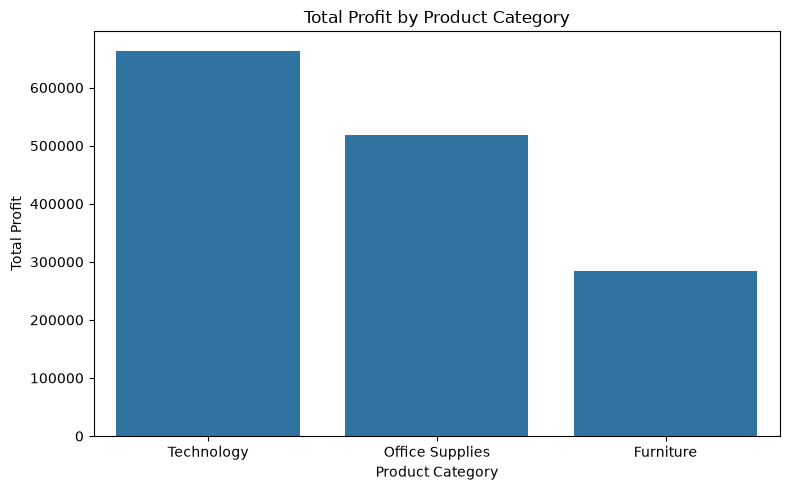

In [60]:
category_profit = (
    df_clean.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Visualization Insight

Technology generates the highest total profit among the three product categories, followed by Office Supplies, while Furniture generates the lowest total profit. This visualization reinforces the earlier profitability analysis and highlights Technology as the strongest category based on total profit.

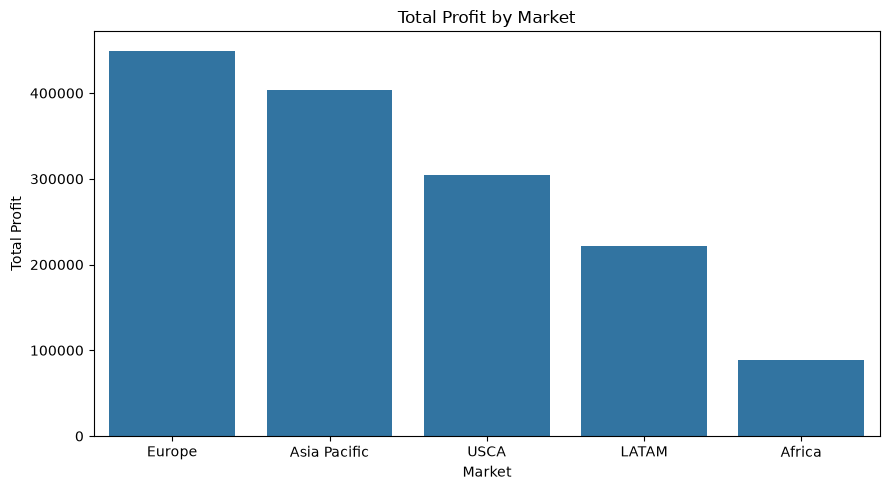

In [61]:
market_profit = (
    df_clean.groupby("Market")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=market_profit.index,
    y=market_profit.values
)

plt.title("Total Profit by Market")
plt.xlabel("Market")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

### Visualization Insight

Europe records the highest total profit, while Africa records the lowest. The visualization highlights substantial differences in total profitability across markets, with Asia Pacific and USCA occupying the middle positions.

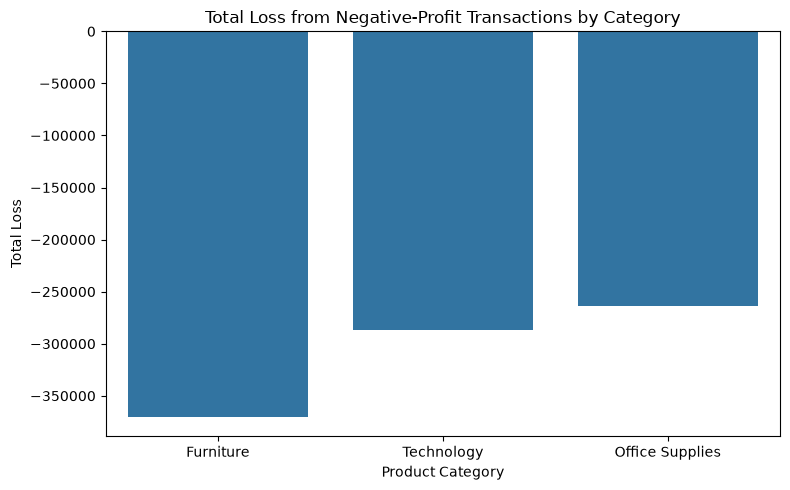

In [62]:
negative_profit = (
    df_clean[df_clean["Profit"] < 0]
    .groupby("Category")["Profit"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=negative_profit.index,
    y=negative_profit.values
)

plt.title("Total Loss from Negative-Profit Transactions by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Loss")
plt.tight_layout()

plt.show()

### Visualization Insight

Furniture records the largest total loss from negative-profit transactions, followed by Technology and Office Supplies. The visualization highlights Furniture as the category with the greatest financial impact from loss-making transactions.

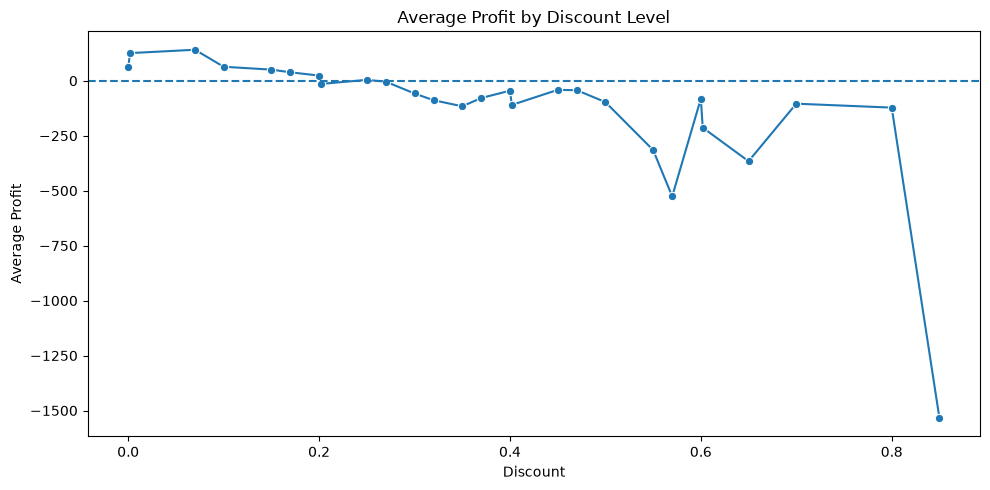

In [63]:
discount_profit = (
    df_clean.groupby("Discount")["Profit"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=discount_profit.index,
    y=discount_profit.values,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.tight_layout()

plt.show()

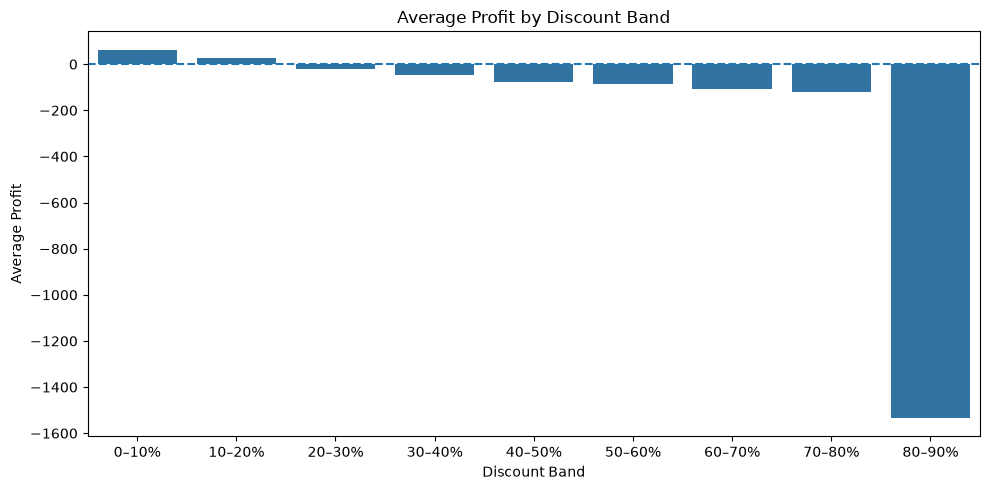

In [65]:
discount_bins = [0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
discount_labels = [
    "0–10%", "10–20%", "20–30%", "30–40%",
    "40–50%", "50–60%", "60–70%", "70–80%", "80–90%"
]

df_clean["Discount Band"] = pd.cut(
    df_clean["Discount"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True
)

discount_band_profit = (
    df_clean.groupby("Discount Band", observed=True)["Profit"]
    .mean()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=discount_band_profit.index,
    y=discount_band_profit.values
)

plt.axhline(0, linestyle="--")

plt.title("Average Profit by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Average Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

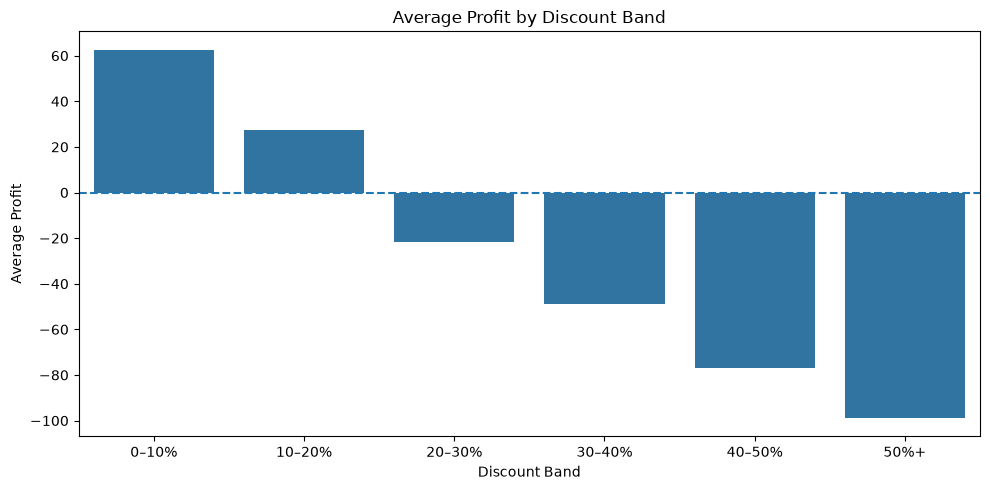

In [66]:
discount_bins = [0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.90]

discount_labels = [
    "0–10%", "10–20%", "20–30%",
    "30–40%", "40–50%", "50%+"
]

df_clean["Discount Band"] = pd.cut(
    df_clean["Discount"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True
)

discount_band_profit = (
    df_clean.groupby("Discount Band", observed=True)["Profit"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=discount_band_profit.index,
    y=discount_band_profit.values
)

plt.axhline(0, linestyle="--")

plt.title("Average Profit by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Average Profit")

plt.tight_layout()
plt.show()

### Visualization Insight

Average profit declines as discount bands increase. Lower discount bands remain profitable, while higher discount bands show increasingly negative average profit, highlighting the potential profitability risk associated with heavy discounting.